# Évaluation de la prédiction salariale

Nous reproduisons le même découpage et la même expérience que dans le notebook 04, avec trois modèles : moyenne globale, moyenne par métier et régression Ridge.
MAE : erreur absolue moyenne en USD (plus petite = meilleure).
RMSE : erreur en USD plus sensible aux grandes erreurs.
R² : score relatif à la variabilité des cibles du test ; un score nul ou négatif
indique que le modèle explique peu ou pas cette variabilité.

In [10]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display
project_root = Path.cwd() if (Path.cwd() / "data/archive").exists() else Path.cwd().parent
sys.path.insert(0, str(project_root))
from src.salary_prediction import evaluate_salary_model
data_dir = project_root / "data/archive"
offres = pd.read_csv(data_dir / "fact_job_postings.csv")
liens = pd.read_csv(data_dir / "bridge_job_skills.csv")
scores, predictions = evaluate_salary_model(offres, liens)
display(scores.round(3))

,MAE_USD,RMSE_USD,R2,n_train,n_test
modele,,,,,
Reference moyenne,31452.332,36998.196,-0.000,44000,11000
Moyenne par metier,17870.604,21318.457,0.668,44000,11000
Regression Ridge,17872.053,21325.897,0.668,44000,11000


,nombre_offres,MAE_modele_USD,MAE_reference_USD,MAE_moyenne_metier_USD
experience_level,,,,
Entry,2760,17775.88,31332.72,17780.98
Lead,2784,17956.09,31214.92,17947.09
Mid,2743,17619.77,31132.48,17619.69
Senior,2713,18138.72,32141.03,18136.98


,nombre_offres,MAE_modele_USD,MAE_reference_USD,MAE_moyenne_metier_USD
country,,,,
Australia,884,17411.55,31715.21,17423.01
Brazil,840,18278.02,32094.85,18304.61
Canada,823,17672.93,30752.89,17665.46
France,888,17577.71,31387.70,17592.24
Germany,867,17693.72,31152.46,17702.36
India,841,18629.43,32189.22,18644.07
Ireland,884,17506.33,30081.85,17505.39
Netherlands,797,17585.37,31022.76,17593.08
Singapore,816,17692.95,31531.13,17673.70


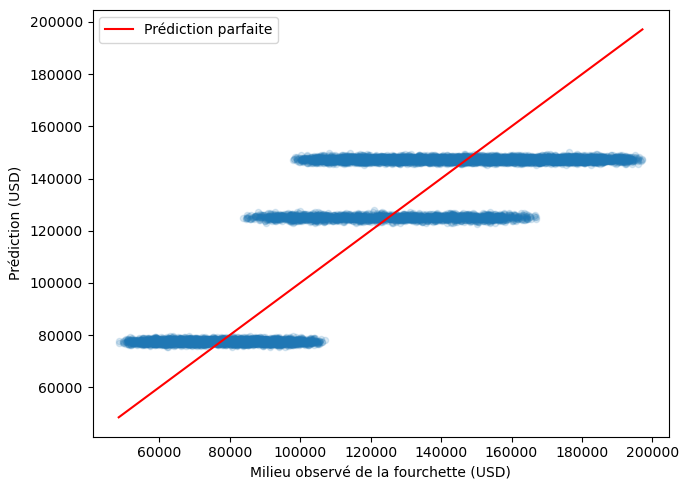

Gain de Ridge par rapport à la moyenne par métier : -1 USD de MAE


In [8]:
import matplotlib.pyplot as plt
erreurs = predictions.merge(offres[["job_id", "experience_level", "country"]], on="job_id", validate="one_to_one")
erreurs["erreur_absolue_modele"] = (erreurs["Regression Ridge"] - erreurs.salaire_cible_usd).abs()
erreurs["erreur_absolue_reference"] = (erreurs["Reference moyenne"] - erreurs.salaire_cible_usd).abs()
erreurs["erreur_absolue_metier"] = (erreurs["Moyenne par metier"] - erreurs.salaire_cible_usd).abs()
for dimension in ["experience_level", "country"]:
    display(erreurs.groupby(dimension).agg(
        nombre_offres=("job_id", "count"),
        MAE_modele_USD=("erreur_absolue_modele", "mean"),
        MAE_reference_USD=("erreur_absolue_reference", "mean"),
        MAE_moyenne_metier_USD=("erreur_absolue_metier", "mean")).round(2))
erreurs.plot.scatter(x="salaire_cible_usd", y="Regression Ridge", alpha=0.15, figsize=(7, 5))
bornes = [erreurs.salaire_cible_usd.min(), erreurs.salaire_cible_usd.max()]
plt.plot(bornes, bornes, color="red", label="Prédiction parfaite")
plt.xlabel("Milieu observé de la fourchette (USD)")
plt.ylabel("Prédiction (USD)")
plt.legend()
plt.tight_layout()
plt.show()
ecart = scores.loc["Moyenne par metier", "MAE_USD"] - scores.loc["Regression Ridge", "MAE_USD"]
print(f"Gain de Ridge par rapport à la moyenne par métier : {ecart:.0f} USD de MAE")

## Limites

Les scores concernent uniquement ce fichier et ce découpage aléatoire. Les intervalles
d'incertitude ne sont pas estimés. Les moyennes d'erreur par pays et expérience permettent
d'inspecter des écarts de performance, sans établir une équité du modèle.
Nous ne validons ni une généralisation à de nouvelles sources ni une prévision temporelle.

## Résultat mesuré sur les données du projet

Sur 44 000 offres d'entraînement et 11 000 offres de test :

| Modèle | MAE (USD) | RMSE (USD) | R² |
|---|---|---|---|
| Référence moyenne | 31 452 | 36 998 | 0,000 |
| Moyenne par métier | 17 871 | 21 318 | 0,668 |
| Régression Ridge | 17 872 | 21 326 | 0,668 |

Ridge réduit l'erreur de **43 %** par rapport à la moyenne globale, mais ne fait **pas mieux que la moyenne par métier**. Les erreurs sont semblables pour tous les pays et tous les niveaux d'expérience, ce qui confirme que ces variables n'apportent pas d'information sur le salaire.

Sur le graphique, les prédictions forment trois bandes horizontales (≈ 77 000, 125 000 et 147 000 USD), une par famille de métiers : le modèle ne sait différencier les offres que par leur métier.

**Conclusion.** Il est possible de prédire en partie le salaire d'une offre (R² = 0,67), mais uniquement grâce au métier. Ce résultat ne garantit pas la précision d'une estimation individuelle (erreur moyenne ≈ 18 000 USD) ni la validité sur un autre marché. Il concerne le milieu de la fourchette, pas le salaire effectivement versé.

In [9]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

project_root = Path.cwd() if (Path.cwd() / "data/archive").exists() else Path.cwd().parent
sys.path.insert(0, str(project_root))

from src.salary_prediction import evaluate_salary_model

data_dir = project_root / "data/archive"
offres = pd.read_csv(data_dir / "fact_job_postings.csv")
liens = pd.read_csv(data_dir / "bridge_job_skills.csv")

scores, predictions = evaluate_salary_model(offres, liens)

display(scores.round(3))

,MAE_USD,RMSE_USD,R2,n_train,n_test
modele,,,,,
Reference moyenne,31452.332,36998.196,-0.000,44000,11000
Moyenne par metier,17870.604,21318.457,0.668,44000,11000
Regression Ridge,17872.053,21325.897,0.668,44000,11000


In [3]:
# Comparer les salaires réels et les salaires prédits
display(predictions.head(10))

,job_id,salaire_cible_usd,Reference moyenne,Moyenne par metier,Regression Ridge
0,JOB-34192,125157.5,121996.25175,125450.044155,125475.080310
1,JOB-23680,93159.5,121996.25175,77597.525773,77267.697346
2,JOB-44685,126725.5,121996.25175,124693.288009,125516.665857
3,JOB-11336,146559.0,121996.25175,124693.288009,124208.944781
4,JOB-22692,184421.5,121996.25175,147485.241910,147201.869606
5,JOB-32405,115737.5,121996.25175,147819.588466,147811.133510
6,JOB-53453,103650.0,121996.25175,125450.044155,125369.837928
7,JOB-50290,163217.0,121996.25175,147030.340407,148091.364808
8,JOB-587,109526.0,121996.25175,147819.588466,147366.730609
9,JOB-23901,96602.0,121996.25175,125450.044155,125540.530765


In [4]:
# Vérifier les colonnes disponibles
print(predictions.columns.tolist())

['job_id', 'salaire_cible_usd', 'Reference moyenne', 'Moyenne par metier', 'Regression Ridge']


In [5]:
# Copier les 10 premières prédictions
erreurs = predictions.head(10).copy()

# Calculer l'erreur : salaire prédit - salaire réel
modeles = [
    "Reference moyenne",
    "Moyenne par metier",
    "Regression Ridge"
]

for modele in modeles:
    erreurs[f"Erreur - {modele}"] = (
        erreurs[modele] - erreurs["salaire_cible_usd"]
    )

display(erreurs.round(2))

,job_id,salaire_cible_usd,Reference moyenne,Moyenne par metier,Regression Ridge,Erreur - Reference moyenne,Erreur - Moyenne par metier,Erreur - Regression Ridge
0,JOB-34192,125157.5,121996.25,125450.04,125475.08,-3161.25,292.54,317.58
1,JOB-23680,93159.5,121996.25,77597.53,77267.70,28836.75,-15561.97,-15891.80
2,JOB-44685,126725.5,121996.25,124693.29,125516.67,-4729.25,-2032.21,-1208.83
3,JOB-11336,146559.0,121996.25,124693.29,124208.94,-24562.75,-21865.71,-22350.06
4,JOB-22692,184421.5,121996.25,147485.24,147201.87,-62425.25,-36936.26,-37219.63
5,JOB-32405,115737.5,121996.25,147819.59,147811.13,6258.75,32082.09,32073.63
6,JOB-53453,103650.0,121996.25,125450.04,125369.84,18346.25,21800.04,21719.84
7,JOB-50290,163217.0,121996.25,147030.34,148091.36,-41220.75,-16186.66,-15125.64
8,JOB-587,109526.0,121996.25,147819.59,147366.73,12470.25,38293.59,37840.73
9,JOB-23901,96602.0,121996.25,125450.04,125540.53,25394.25,28848.04,28938.53


In [6]:
# Comparer les erreurs absolues sur toutes les prédictions
modeles = [
    "Reference moyenne",
    "Moyenne par metier",
    "Regression Ridge"
]

comparaison_erreurs = pd.DataFrame({
    "Modele": modeles,
    "MAE_calcule": [
        (predictions[m] - predictions["salaire_cible_usd"]).abs().mean()
        for m in modeles
    ]
})

display(comparaison_erreurs.round(2))

,Modele,MAE_calcule
0,Reference moyenne,31452.33
1,Moyenne par metier,17870.60
2,Regression Ridge,17872.05


Conclusion de l'évaluation des modèles

Trois approches ont été comparées pour prédire les salaires des offres d'emploi : une référence basée sur la moyenne globale, une moyenne par métier et une régression Ridge.

La référence globale obtient une MAE de 31 452,33 USD et un R² proche de 0. Les deux autres modèles améliorent nettement les résultats : la moyenne par métier atteint une MAE de 17 870,60 USD et un R² de 0,668, tandis que la régression Ridge atteint une MAE de 17 872,05 USD et un R² de 0,668.

La moyenne par métier obtient la plus faible MAE, mais l'écart avec Ridge est très faible. Ces résultats montrent que le métier constitue une information importante pour estimer les salaires dans ce jeu de données.

Les prédictions restent toutefois imparfaites, comme le montrent les écarts observés sur certaines offres. Il serait pertinent d'étudier les erreurs selon les métiers et de tester d'autres variables afin d'améliorer les estimations.

Limite : ces résultats mesurent les performances sur le jeu de test utilisé. Ils ne garantissent pas les mêmes performances sur de nouvelles offres d'emploi.

 Métrique retenue : MAE

La MAE (*Mean Absolute Error*, ou erreur absolue moyenne) mesure l'écart absolu moyen entre les salaires prédits par le modèle et les salaires réels.

Pour le modèle « Moyenne par métier », la MAE obtenue est de **17 870,60 USD**. Cela signifie que les prédictions s'écartent en moyenne d'environ 17 871 USD des salaires réels, sur le jeu de test.

Plus la MAE est faible, plus les prédictions sont proches des valeurs réelles.

Limite du modèle : les prédictions peuvent présenter des écarts importants pour certaines offres d'emploi. La MAE résume l'erreur moyenne, mais ne reflète pas à elle seule toutes les erreurs individuelles. De plus, les performances mesurées sur le jeu de test ne garantissent pas les mêmes résultats sur de nouvelles offres.